# Tahap 4 — Analisis Data Eksploratif

Keputusan D6: panduan orde musiman ditentukan dari data setiap deret; tidak ada
komponen musiman yang dipaksakan.

In [1]:
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
SEED = int(CFG["seed"])
np.random.seed(SEED)

def rp(*parts: str) -> Path:
    """Resolve a repo-relative path (parts are path fragments under the repo root)."""
    return ROOT.joinpath(*parts)

BRAND_COLORS = {"OPPO": "#0072B2", "Realme": "#D55E00", "Samsung": "#009E73",
                "Vivo": "#CC79A7", "Xiaomi": "#E69F00"}
ALGO_COLORS = {"SARIMAX": "#0072B2", "RF": "#D55E00", "LSTM": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5),
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

## Memuat artefak mingguan

Panel Tahap 2 menyimpan 20 deret gerai × merek dengan kalender mingguan yang
sama. Analisis berikut tetap mandiri di notebook ini.

In [2]:
weekly = pd.read_parquet(rp("data", "interim", "weekly_store_brand.parquet"))
weekly.head()

,store,brand,week_start,units
0,Toko_A,OPPO,2021-12-27,0
1,Toko_A,OPPO,2022-01-03,3
2,Toko_A,OPPO,2022-01-10,3
3,Toko_A,OPPO,2022-01-17,0
4,Toko_A,OPPO,2022-01-24,8


## Fungsi deret dan pengujian stasioneritas

ADF mengarahkan orde diferensiasi `d`; kekuatan musiman Hyndman mengarahkan
`D` secara data-driven untuk keputusan D6.

In [3]:
import logging
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

logger = logging.getLogger(__name__)

SEASONAL_PERIOD = int(CFG["seasonal_period"])
ADF_ALPHA = 0.05
SEASONAL_STRENGTH_THRESH = 0.64
MAX_D = 2
LEBARAN_DATES = ["2022-05-02", "2023-04-22", "2024-04-10", "2025-03-31"]


def load_weekly(path: str | Path) -> pd.DataFrame:
    """Muat panel mingguan Tahap 2 (long: store, brand, week_start, units)."""
    return pd.read_parquet(path)


def series_key(store: str, brand: str) -> str:
    return f"{store}|{brand}"


def to_series(weekly: pd.DataFrame, store: str, brand: str) -> pd.Series:
    """Ekstrak satu deret waktu (index = week_start Senin, values = units)."""
    sub = weekly[(weekly["store"] == store) & (weekly["brand"] == brand)]
    return sub.set_index("week_start")["units"].sort_index().astype(float)


def series_list(weekly: pd.DataFrame) -> list[tuple[str, str]]:
    return sorted(weekly.groupby(["store", "brand"]).groups.keys())


def adf_pvalue(series: pd.Series) -> float | None:
    """p-value ADF (autolag=AIC); None bila deret konstan/gagal."""
    s = series.dropna()
    if s.nunique() <= 1 or len(s) < 12:
        return None
    try:
        return float(adfuller(s, autolag="AIC")[1])
    except Exception as exc:  # noqa: BLE001
        logger.warning("ADF gagal: %s", exc)
        return None


def seasonal_strength(series: pd.Series, period: int = SEASONAL_PERIOD) -> float | None:
    """Kekuatan Fs = max(0, 1 - Var(resid)/Var(resid+musiman)) Hyndman."""
    s = series.dropna()
    if len(s) < 2 * period or s.nunique() <= 1:
        return None
    try:
        dec = seasonal_decompose(s, model="additive", period=period)
        resid = dec.resid.dropna()
        seas = dec.seasonal.reindex(resid.index)
        denom = float(np.var(resid + seas))
        if denom <= 0:
            return 0.0
        return float(max(0.0, 1.0 - np.var(resid) / denom))
    except Exception as exc:  # noqa: BLE001
        logger.warning("Dekomposisi musiman gagal: %s", exc)
        return None


def recommend_orders(series: pd.Series, period: int = SEASONAL_PERIOD) -> dict:
    """Rekomendasi d (ADF berjenjang) dan D (kekuatan musiman)."""
    p_level = adf_pvalue(series)
    d = 0
    if p_level is not None and p_level >= ADF_ALPHA:
        p1 = adf_pvalue(series.diff().dropna())
        d = 1 if (p1 is not None and p1 < ADF_ALPHA) else MAX_D
    fs = seasonal_strength(series, period)
    D = 1 if (fs is not None and fs >= SEASONAL_STRENGTH_THRESH) else 0
    return {
        "p_value_level": None if p_level is None else round(p_level, 4),
        "stationary_level": None if p_level is None else bool(p_level < ADF_ALPHA),
        "seasonal_strength": None if fs is None else round(fs, 4),
        "recommend_d": d,
        "recommend_D": D,
    }


def run_adf_all(weekly: pd.DataFrame) -> dict[str, dict]:
    """ADF dan rekomendasi orde untuk seluruh deret."""
    return {
        series_key(store, brand): recommend_orders(to_series(weekly, store, brand))
        for store, brand in series_list(weekly)
    }

## Visualisasi deret dan musiman

Warna merek mengikuti palet Okabe–Ito. Dekomposisi bersifat aditif karena
deret penjualan dapat mengandung nol.

In [4]:
def plot_series_grid(weekly: pd.DataFrame, out_path: Path) -> Path:
    """Grid deret mingguan gerai × merek."""
    stores = sorted(weekly["store"].unique())
    brands = sorted(weekly["brand"].unique())
    fig, axes = plt.subplots(len(stores), len(brands), figsize=(20, 12),
                             sharex=True, squeeze=False)
    for i, store in enumerate(stores):
        for j, brand in enumerate(brands):
            ax = axes[i][j]
            s = to_series(weekly, store, brand)
            ax.plot(s.index, s.values, lw=0.8, color=BRAND_COLORS[brand])
            if i == 0:
                ax.set_title(brand, fontsize=11)
            if j == 0:
                ax.set_ylabel(store, fontsize=11)
    for ax in axes[-1]:
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=(7,)))
    fig.suptitle("Deret mingguan unit terjual — gerai × merek (4×5)", fontsize=14)
    fig.tight_layout(rect=(0.03, 0.03, 1, 0.98))
    fig.supxlabel("Minggu", y=0.008, fontsize=12)
    fig.supylabel("Unit terjual per minggu", x=0.008, fontsize=12)
    fig.savefig(out_path, dpi=110)
    plt.close(fig)
    return out_path


def plot_acf_pacf(series: pd.Series, name: str, out_path: Path, lags: int = 60) -> Path:
    """ACF dan PACF berdampingan untuk satu deret."""
    lags = min(lags, len(series.dropna()) // 2 - 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(series.dropna(), ax=ax1, lags=lags)
    ax1.set_title(f"ACF — {name}")
    ax1.set_xlabel("Lag (minggu)")
    ax1.set_ylabel("Autokorelasi")
    plot_pacf(series.dropna(), ax=ax2, lags=lags, method="ywm")
    ax2.set_title(f"PACF — {name}")
    ax2.set_xlabel("Lag (minggu)")
    ax2.set_ylabel("Autokorelasi parsial")
    fig.tight_layout()
    fig.savefig(out_path, dpi=110)
    plt.close(fig)
    return out_path


def plot_decompose(series: pd.Series, name: str, out_path: Path,
                   period: int = SEASONAL_PERIOD) -> Path:
    """Dekomposisi musiman aditif untuk deret terpadat."""
    dec = seasonal_decompose(series.dropna(), model="additive", period=period)
    fig = dec.plot()
    fig.set_size_inches(12, 8)
    for ax, label in zip(fig.axes, ["Teramati", "Tren", "Musiman", "Residual"]):
        ax.set_ylabel(label)
    observed_title = "Deret unit terjual teramati"
    fig.axes[0].set_title(observed_title)
    assert fig.axes[0].get_title() == observed_title
    fig.suptitle(f"Dekomposisi musiman (periode={period}) — {name}", y=1.01)
    fig.tight_layout(rect=(0, 0.04, 1, 0.98))
    fig.supxlabel("Minggu", y=0.01)
    fig.savefig(out_path, dpi=110, bbox_inches="tight")
    plt.close(fig)
    return out_path


def plot_seasonality_month(weekly: pd.DataFrame, out_path: Path) -> Path:
    """Rata-rata unit per bulan, agregat lintas deret."""
    monthly = weekly.assign(month=weekly["week_start"].dt.month)
    m = monthly.groupby("month")["units"].mean()
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(m.index, m.values, color="#56B4E9")
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Bulan")
    ax.set_ylabel("Rata-rata unit per minggu-deret")
    ax.set_title("Musiman: rata-rata unit per bulan (Lebaran Mar–Mei, Harbolnas Nov–Des)")
    fig.tight_layout()
    fig.savefig(out_path, dpi=110)
    plt.close(fig)
    return out_path

Uji visual berikut memeriksa objek figure langsung, bukan teks sumber atau OCR.

In [5]:
import tempfile

captured_figures = []
original_close = plt.close
try:
    plt.close = lambda fig=None: captured_figures.append(fig)
    with tempfile.TemporaryDirectory() as temp_dir:
        plot_decompose(
            to_series(weekly, "Toko_A", "Xiaomi"),
            "Toko_A|Xiaomi",
            Path(temp_dir) / "probe_decompose.png",
        )
finally:
    plt.close = original_close

observed_subplot_title = captured_figures[0].axes[0].get_title()
assert observed_subplot_title == "Deret unit terjual teramati", observed_subplot_title
original_close(captured_figures[0])

## Ringkasan dan orkestrasi

Ringkasan JSON menyimpan artefak dengan path relatif terhadap repositori agar
dapat dipindahkan bersama proyek.

In [6]:
def seasonal_summary(weekly: pd.DataFrame) -> dict:
    """Rata-rata musiman dan anotasi Lebaran/Harbolnas."""
    w = weekly.copy()
    w["month"] = w["week_start"].dt.month
    w["woy"] = w["week_start"].dt.isocalendar().week.astype(int)
    by_month = w.groupby("month")["units"].mean().round(3)
    by_woy = w.groupby("woy")["units"].mean().round(3)
    grid = pd.DatetimeIndex(sorted(w["week_start"].unique()))
    lebaran_weeks = []
    for date in pd.to_datetime(LEBARAN_DATES):
        monday = date.to_period("W").start_time
        if monday in grid:
            lebaran_weeks.append(monday.date().isoformat())
    return {
        "mean_units_by_month": {int(k): float(v) for k, v in by_month.items()},
        "mean_units_by_weekofyear": {int(k): float(v) for k, v in by_woy.items()},
        "lebaran_weeks": lebaran_weeks,
        "harbolnas_note": "Puncak belanja daring Nov–Des (11.11, 12.12); cek bulan 11–12.",
        "peak_month": int(by_month.idxmax()),
        "trough_month": int(by_month.idxmin()),
    }


def run_eda(weekly: pd.DataFrame, figures_dir: Path, results_dir: Path) -> dict:
    """Jalankan EDA, tulis figur dan eda_summary.json, lalu kembalikan ringkasan."""
    figures_dir.mkdir(parents=True, exist_ok=True)
    results_dir.mkdir(parents=True, exist_ok=True)
    totals = weekly.groupby(["store", "brand"])["units"].sum().sort_values(ascending=False)
    keys = list(totals.index)
    densest = keys[0]
    representative = [keys[0], keys[len(keys) // 2], keys[-1]]

    figures: list[str] = []
    plot_series_grid(weekly, figures_dir / "series_grid.png")
    figures.append("reports/figures/series_grid.png")
    for store, brand in representative:
        filename = f"acf_pacf_{store}_{brand}.png"
        plot_acf_pacf(to_series(weekly, store, brand), series_key(store, brand), figures_dir / filename)
        figures.append(f"reports/figures/{filename}")
    d_store, d_brand = densest
    filename = f"decompose_{d_store}_{d_brand}.png"
    plot_decompose(to_series(weekly, d_store, d_brand), series_key(d_store, d_brand), figures_dir / filename)
    figures.append(f"reports/figures/{filename}")
    plot_seasonality_month(weekly, figures_dir / "seasonality_month.png")
    figures.append("reports/figures/seasonality_month.png")

    adf = run_adf_all(weekly)
    n_stat = sum(1 for value in adf.values() if value["stationary_level"] is True)
    d_vals = [value["recommend_d"] for value in adf.values()]
    D_vals = [value["recommend_D"] for value in adf.values()]
    summary = {
        "n_series": len(adf),
        "n_weeks": int(weekly.groupby(["store", "brand"]).size().iloc[0]),
        "densest_series": series_key(*densest),
        "representative_series": [series_key(*key) for key in representative],
        "adf": adf,
        "adf_summary": {
            "n_stationary_level": n_stat,
            "n_nonstationary_level": len(adf) - n_stat,
        },
        "recommended_orders": {
            "d_mode": int(pd.Series(d_vals).mode().iloc[0]),
            "D_mode": int(pd.Series(D_vals).mode().iloc[0]),
        },
        "seasonality": seasonal_summary(weekly),
        "figures": figures,
    }
    out_json = results_dir / "eda_summary.json"
    out_json.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
    logger.info(
        "EDA: %d figur, %d/%d deret stasioner (level), d_mode=%d D_mode=%d -> %s",
        len(figures), n_stat, len(adf), summary["recommended_orders"]["d_mode"],
        summary["recommended_orders"]["D_mode"], out_json,
    )
    return summary

## Jalankan EDA dan tampilkan artefak penerimaan

Empat PNG utama ditampilkan secara eksplisit agar tersimpan sebagai keluaran
`image/png` dalam notebook yang telah dieksekusi.

In [7]:
summary = run_eda(
    weekly,
    rp("reports", "figures"),
    rp("reports", "results"),
)
summary

{'n_series': 20,
 'n_weeks': 184,
 'densest_series': 'Toko_A|Xiaomi',
 'representative_series': ['Toko_A|Xiaomi', 'Toko_C|Xiaomi', 'Toko_D|Vivo'],
 'adf': {'Toko_A|OPPO': {'p_value_level': 0.0241,
   'stationary_level': True,
   'seasonal_strength': 0.5133,
   'recommend_d': 0,
   'recommend_D': 0},
  'Toko_A|Realme': {'p_value_level': 0.4362,
   'stationary_level': False,
   'seasonal_strength': 0.413,
   'recommend_d': 1,
   'recommend_D': 0},
  'Toko_A|Samsung': {'p_value_level': 0.0,
   'stationary_level': True,
   'seasonal_strength': 0.4457,
   'recommend_d': 0,
   'recommend_D': 0},
  'Toko_A|Vivo': {'p_value_level': 0.0,
   'stationary_level': True,
   'seasonal_strength': 0.3617,
   'recommend_d': 0,
   'recommend_D': 0},
  'Toko_A|Xiaomi': {'p_value_level': 0.0284,
   'stationary_level': True,
   'seasonal_strength': 0.5518,
   'recommend_d': 0,
   'recommend_D': 0},
  'Toko_B|OPPO': {'p_value_level': 0.0,
   'stationary_level': True,
   'seasonal_strength': 0.5276,
   'recom

In [8]:
adf_table = (
    pd.DataFrame(summary["adf"]).T
    .rename_axis("Gerai|Merek")
    .sort_index()
)
display(adf_table)
pd.DataFrame([summary["adf_summary"] | summary["recommended_orders"]])

,p_value_level,stationary_level,seasonal_strength,recommend_d,recommend_D
Gerai|Merek,,,,,
Toko_A|OPPO,0.0241,True,0.5133,0,0
Toko_A|Realme,0.4362,False,0.413,1,0
Toko_A|Samsung,0.0,True,0.4457,0,0
Toko_A|Vivo,0.0,True,0.3617,0,0
Toko_A|Xiaomi,0.0284,True,0.5518,0,0
Toko_B|OPPO,0.0,True,0.5276,0,0
Toko_B|Realme,0.6533,False,0.549,1,0
Toko_B|Samsung,0.0,True,0.4972,0,0
Toko_B|Vivo,0.0001,True,0.3835,0,0


,n_stationary_level,n_nonstationary_level,d_mode,D_mode
0,17,3,0,0


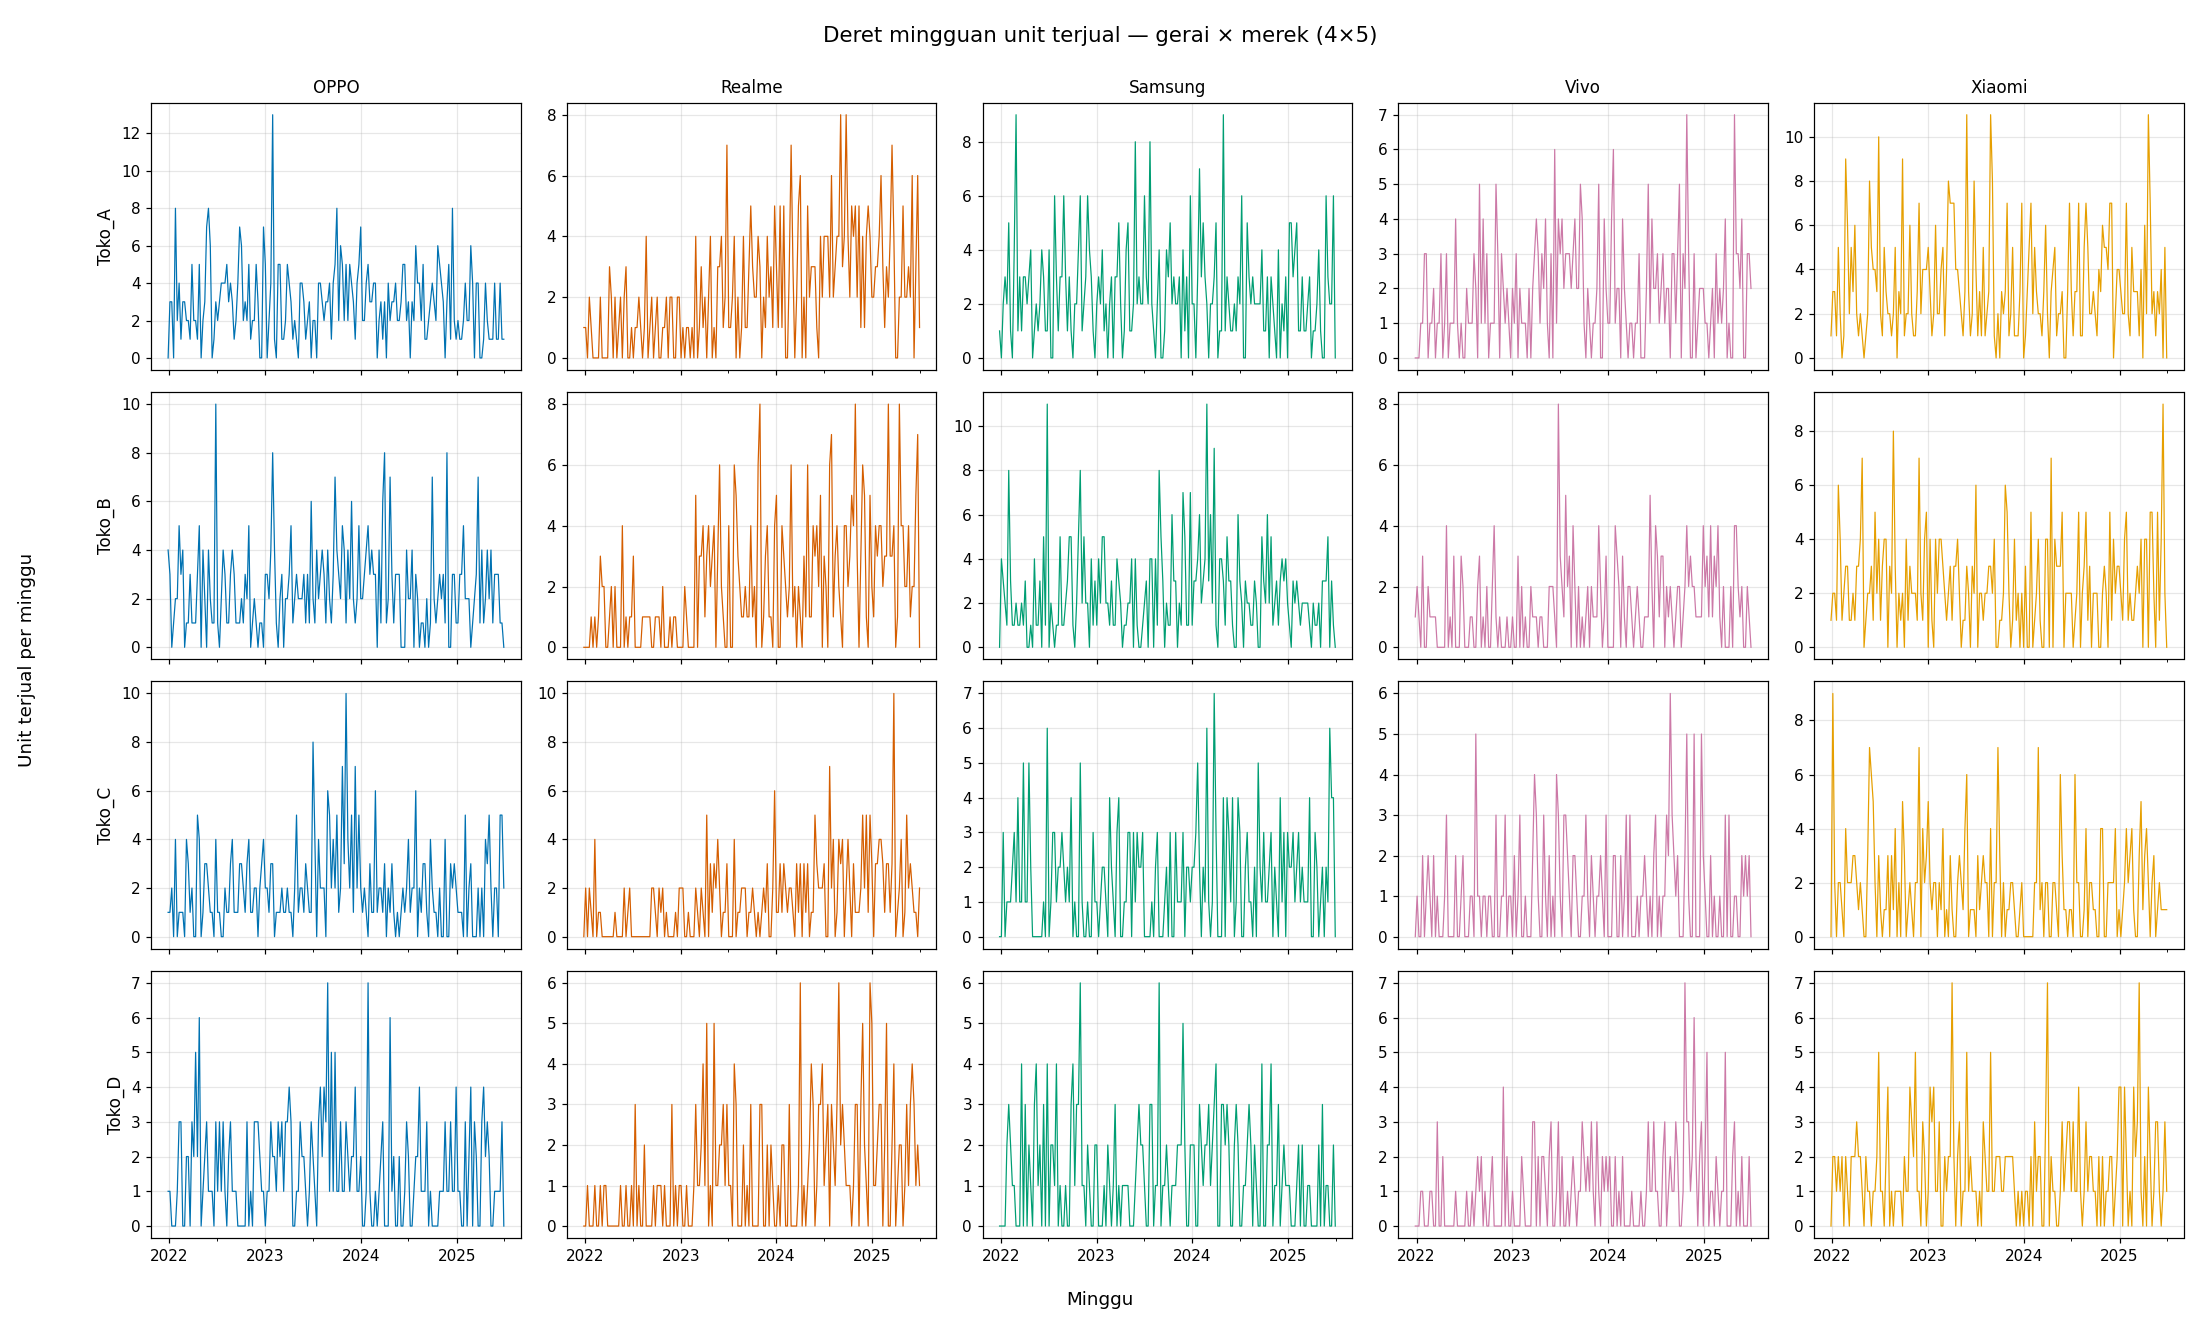

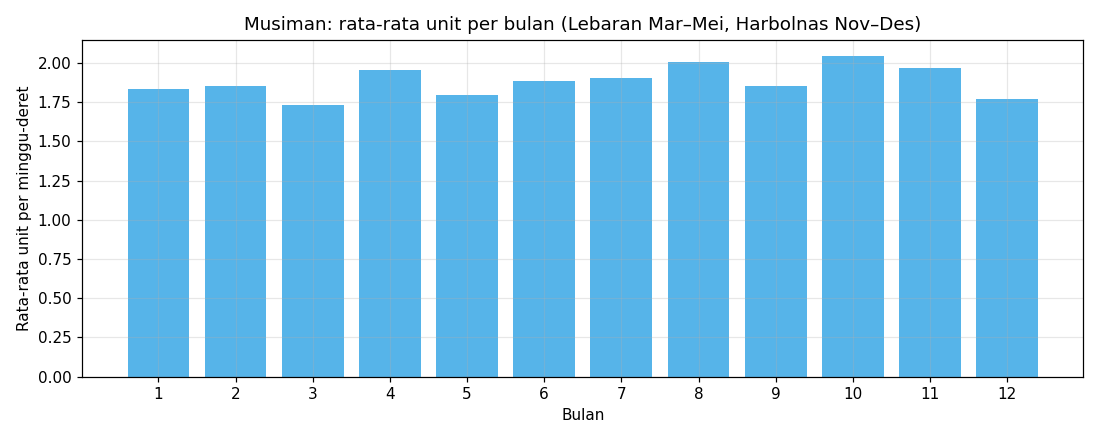

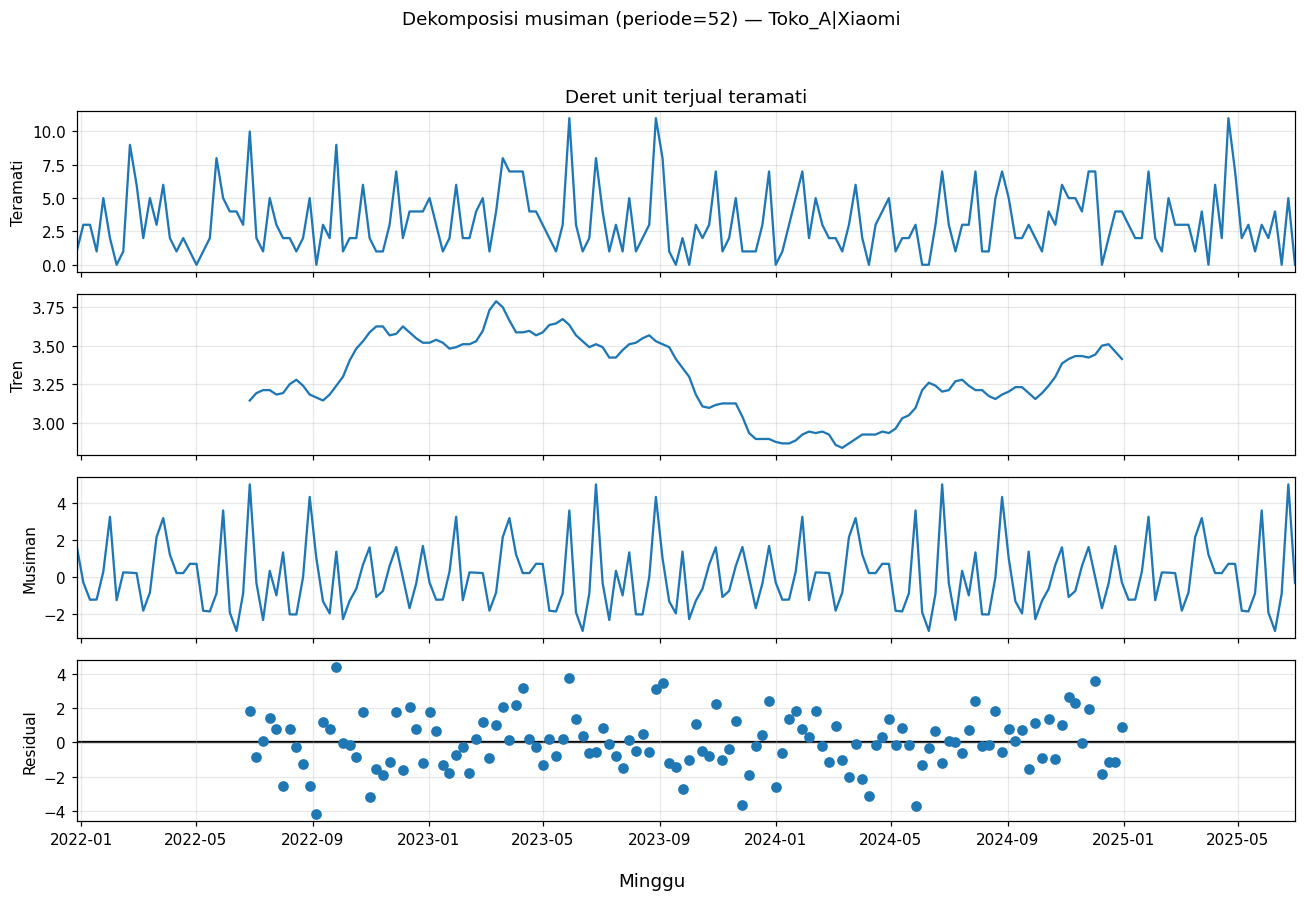

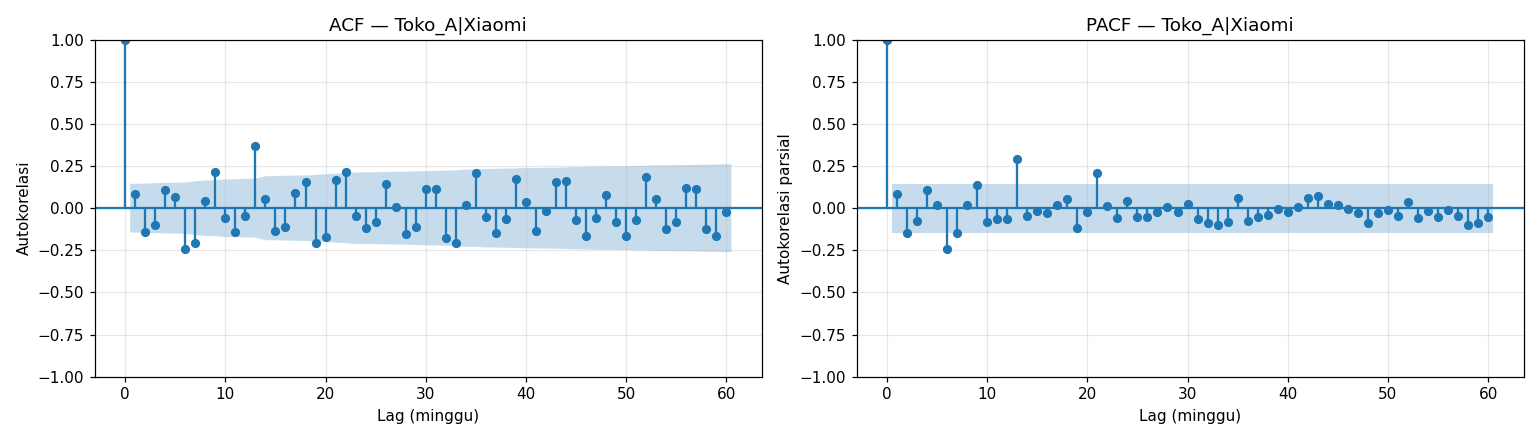

In [9]:
from IPython.display import Image, display

for figure_name in [
    "series_grid.png",
    "seasonality_month.png",
    "decompose_Toko_A_Xiaomi.png",
    "acf_pacf_Toko_A_Xiaomi.png",
]:
    display(Image(filename=str(rp("reports", "figures", figure_name))))

In [10]:
summ = json.loads(rp("reports", "results", "eda_summary.json").read_text(encoding="utf-8"))
assert len(summ["adf"]) == 20
n_stat = sum(1 for result in summ["adf"].values()
             if result["p_value_level"] is not None and result["p_value_level"] < 0.05)
assert n_stat == 17, f"stasioner={n_stat}, diharapkan 17"
for figure_name in ["series_grid.png", "seasonality_month.png",
                    "decompose_Toko_A_Xiaomi.png", "acf_pacf_Toko_A_Xiaomi.png"]:
    figure_path = rp("reports", "figures", figure_name)
    assert figure_path.exists() and figure_path.stat().st_size > 0, figure_name
print(f"✅ Tahap 4: ADF 20 deret, {n_stat}/20 stasioner (p<0,05); figur EDA lengkap")

✅ Tahap 4: ADF 20 deret, 17/20 stasioner (p<0,05); figur EDA lengkap
